In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "../data/processed/crowd_features.csv"
)

df.head()

,timestamp,total_people,zone_a,zone_b,zone_c,zone_d,avg_movement,entries,exits,net_change
0,2026-09-27 01:09:24,1,0,0,0,1,0.00,0,0,0
1,2026-09-27 01:09:24,1,0,0,0,1,38.28,0,0,0
2,2026-09-27 01:09:24,1,0,0,0,1,10.30,0,0,0
3,2026-09-27 01:09:24,1,0,0,0,1,24.60,0,0,0
4,2026-09-27 01:09:25,1,0,0,0,1,8.25,0,0,0


In [3]:
df.shape

(3789, 10)

In [4]:
df.columns

Index(['timestamp', 'total_people', 'zone_a', 'zone_b', 'zone_c', 'zone_d',
       'avg_movement', 'entries', 'exits', 'net_change'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3789 entries, 0 to 3788
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     3789 non-null   str    
 1   total_people  3789 non-null   int64  
 2   zone_a        3789 non-null   int64  
 3   zone_b        3789 non-null   int64  
 4   zone_c        3789 non-null   int64  
 5   zone_d        3789 non-null   int64  
 6   avg_movement  3789 non-null   float64
 7   entries       3789 non-null   int64  
 8   exits         3789 non-null   int64  
 9   net_change    3789 non-null   int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 296.1 KB


In [6]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"]
)

In [7]:
df = df.sort_values(
    "timestamp"
).reset_index(drop=True)

In [8]:
df.isnull().sum()

timestamp       0
total_people    0
zone_a          0
zone_b          0
zone_c          0
zone_d          0
avg_movement    0
entries         0
exits           0
net_change      0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(2632)

In [10]:
df = df.drop_duplicates()

In [11]:
df["people_change"] = (
    df["total_people"].diff()
)

In [12]:
df.describe()

,timestamp,total_people,zone_a,zone_b,zone_c,zone_d,avg_movement,entries,exits,net_change,people_change
count,1157,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.000000,1157.0,1157.000000,1157.000000,1156.000000
mean,2026-09-28 08:52:38.496110,0.980985,0.023336,0.035436,0.309421,0.612792,6.808150,0.0,0.787381,-0.787381,0.000000
min,2026-09-27 01:09:24,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-2.000000,-1.000000
25%,2026-09-27 01:12:31,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-1.000000,0.000000
50%,2026-09-27 01:17:15,1.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.0,1.000000,-1.000000,0.000000
75%,2026-09-29 02:02:25,1.000000,0.000000,0.000000,1.000000,1.000000,10.050000,0.0,1.000000,0.000000,0.000000
max,2026-09-30 23:41:50,2.000000,2.000000,1.000000,1.000000,2.000000,80.060000,0.0,2.000000,0.000000,2.000000
std,NaN,0.154465,0.156657,0.184960,0.462455,0.489094,8.572747,0.0,0.601106,0.601106,0.186097


In [13]:
df["zone_total"] = (
    df["zone_a"]
    + df["zone_b"]
    + df["zone_c"]
    + df["zone_d"]
)

In [14]:
df[
    df["total_people"] != df["zone_total"]
]

,timestamp,total_people,zone_a,zone_b,zone_c,zone_d,avg_movement,entries,exits,net_change,people_change,zone_total


In [15]:
calculated_net = (
    df["entries"] - df["exits"]
)

(df["net_change"] != calculated_net).sum()

np.int64(0)

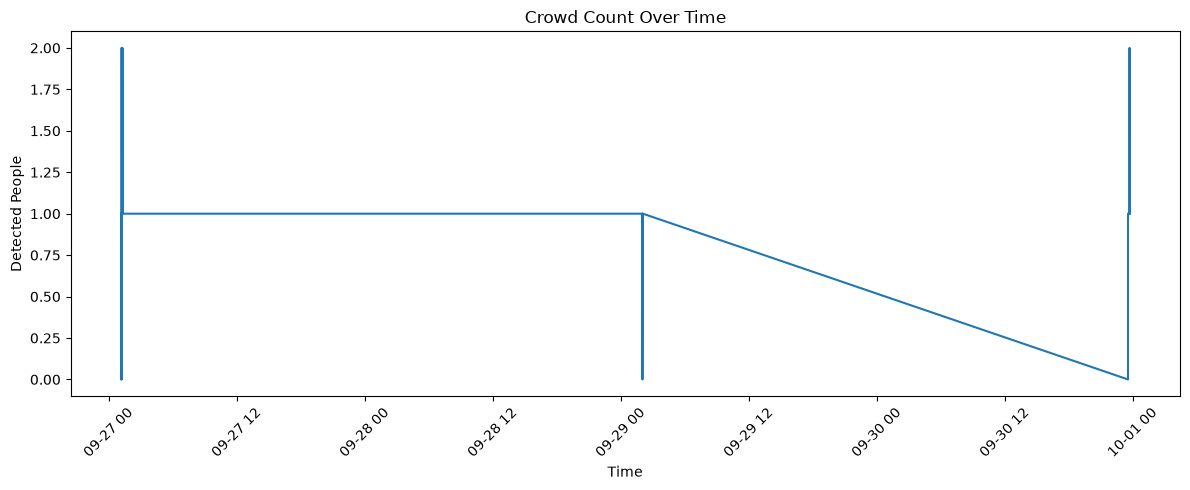

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["total_people"]
)

plt.xlabel("Time")
plt.ylabel("Detected People")
plt.title("Crowd Count Over Time")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

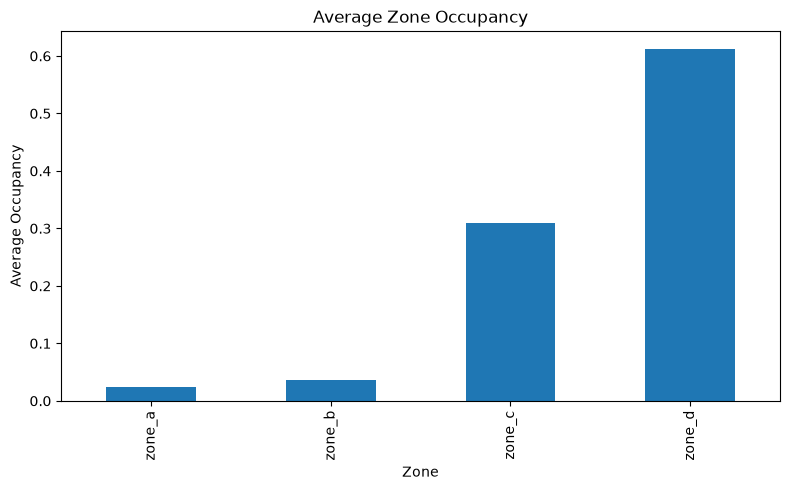

In [17]:
zone_columns = [
    "zone_a",
    "zone_b",
    "zone_c",
    "zone_d"
]

df[zone_columns].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Zone")
plt.ylabel("Average Occupancy")
plt.title("Average Zone Occupancy")

plt.tight_layout()

plt.show()

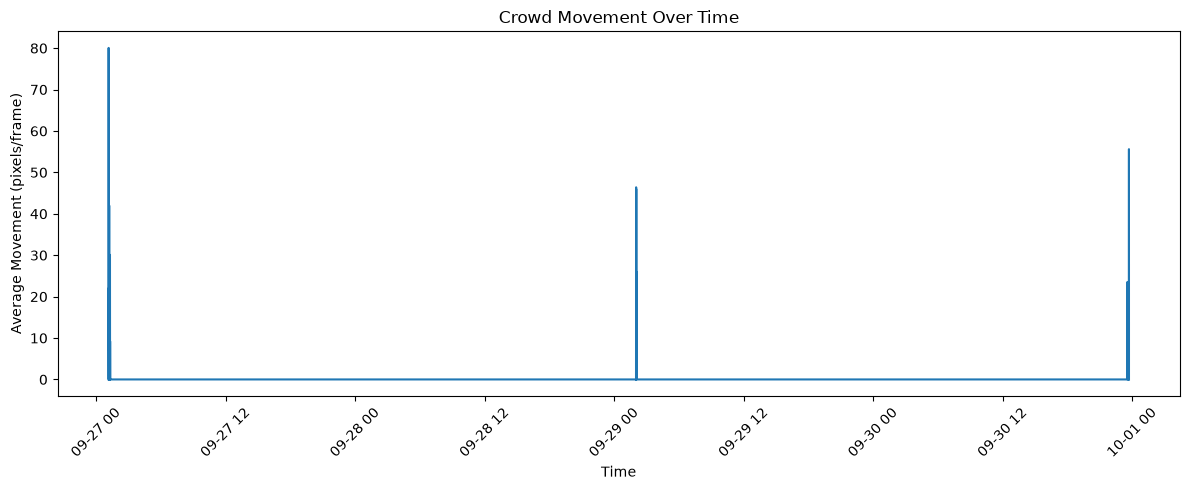

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["avg_movement"]
)

plt.xlabel("Time")
plt.ylabel("Average Movement (pixels/frame)")
plt.title("Crowd Movement Over Time")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

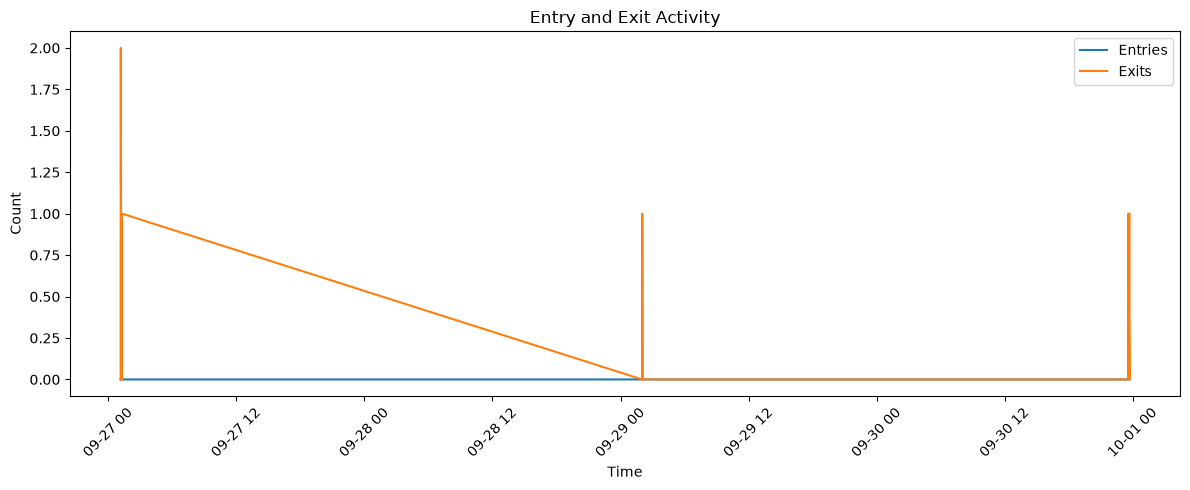

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["entries"],
    label="Entries"
)

plt.plot(
    df["timestamp"],
    df["exits"],
    label="Exits"
)

plt.xlabel("Time")
plt.ylabel("Count")
plt.title("Entry and Exit Activity")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

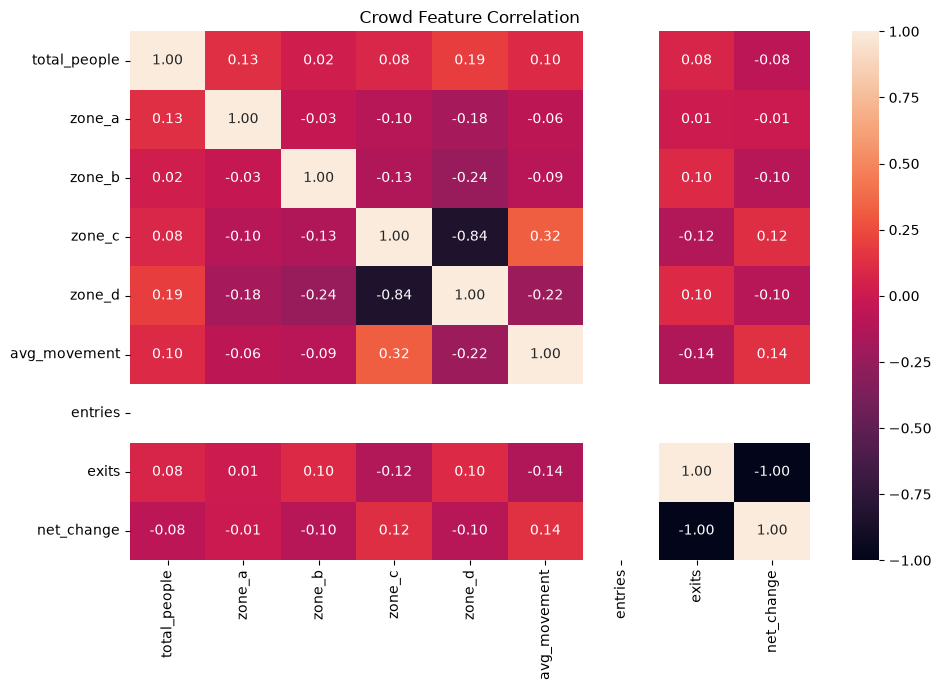

In [20]:
numeric_columns = [
    "total_people",
    "zone_a",
    "zone_b",
    "zone_c",
    "zone_d",
    "avg_movement",
    "entries",
    "exits",
    "net_change"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title(
    "Crowd Feature Correlation"
)

plt.tight_layout()

plt.show()

In [21]:
df["rolling_people_mean"] = (
    df["total_people"]
    .rolling(window=10)
    .mean()
)

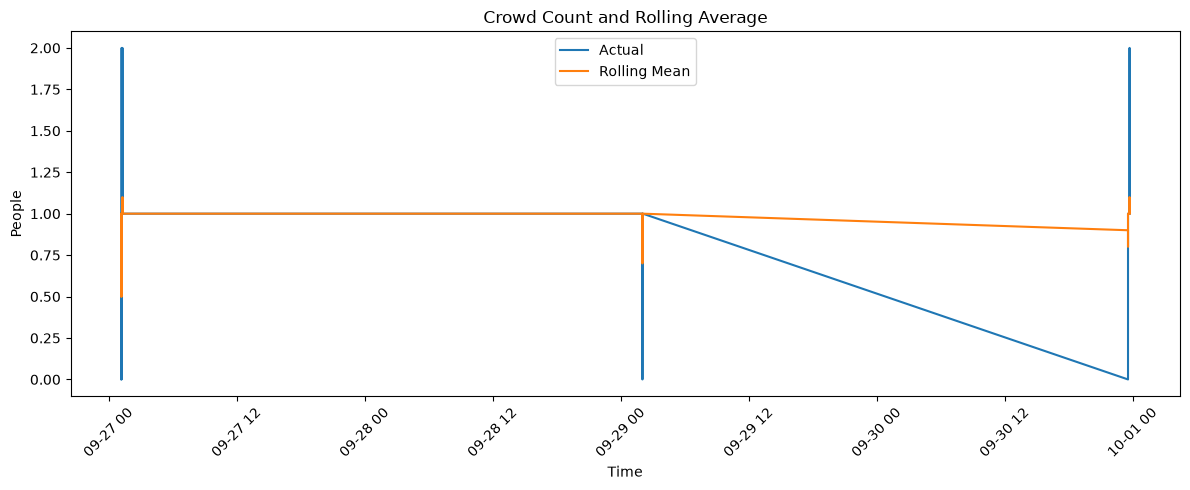

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["total_people"],
    label="Actual"
)

plt.plot(
    df["timestamp"],
    df["rolling_people_mean"],
    label="Rolling Mean"
)

plt.xlabel("Time")
plt.ylabel("People")
plt.title("Crowd Count and Rolling Average")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

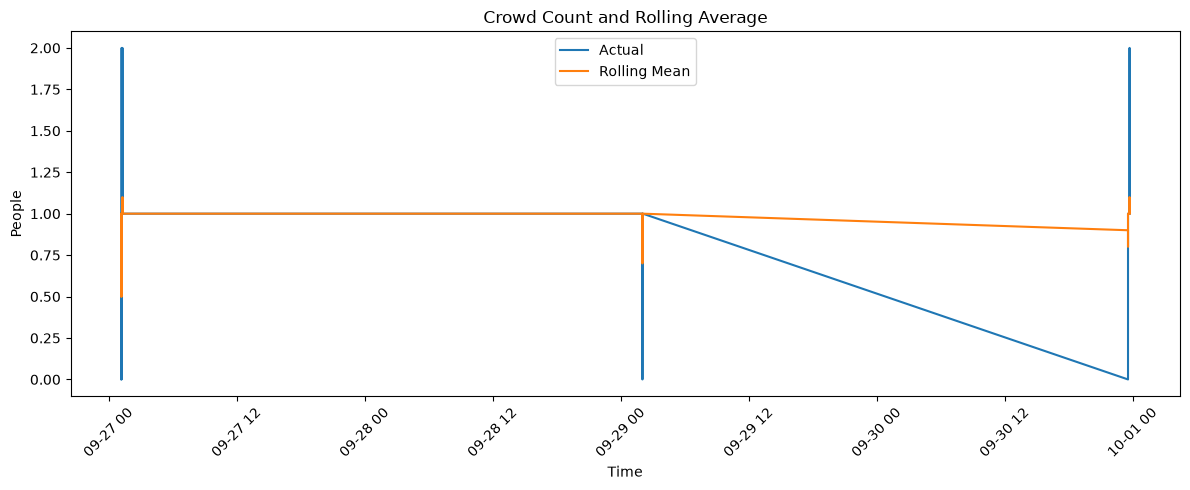

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["total_people"],
    label="Actual"
)

plt.plot(
    df["timestamp"],
    df["rolling_people_mean"],
    label="Rolling Mean"
)

plt.xlabel("Time")
plt.ylabel("People")
plt.title("Crowd Count and Rolling Average")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [24]:
df.to_csv(
    "../data/processed/crowd_features_eda.csv",
    index=False
)